# Módulo 49: Diseño de dashboards

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m49-diseno-de-dashboards-guia.ipynb) y [solución](m49-diseno-de-dashboards-solucion.ipynb). No es una tarea entregada del programa.

Con los módulos anteriores ya podemos limpiar datos, modelarlos, calcular medidas y hacer gráficos interactivos. Falta lo que decide si alguien usará el tablero: que se entienda. Un dashboard compite por unos segundos de atención, y en ese tiempo el lector tiene que encontrar la respuesta a su pregunta. Esta lección reúne los principios de diseño y las herramientas de Streamlit y Plotly para organizar páginas, guiar la navegación y mantener un estilo coherente. El resultado es la app final de la sección, en [`../practica-ventas/app.py`](../practica-ventas/app.py).

1. Principios de diseño
2. La cuadrícula en Streamlit
3. Elegir el gráfico adecuado
4. Antes y después: un gráfico mejorado
5. Temas: `config.toml` y una plantilla de Plotly
6. Navegación entre páginas
7. Marcadores: estados guardados de los filtros
8. Botones y acciones
9. Pantallas estrechas
10. Errores frecuentes
11. Ejercicio

In [1]:
import sys
from pathlib import Path

import plotly.express as px
import plotly.io as pio
import streamlit.config
import streamlit.logger
from streamlit.testing.v1 import AppTest

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450
# Sin mensajes del registro de Streamlit en las salidas (los errores se leen con at.exception)
streamlit.config.set_option("logger.level", "critical")
streamlit.logger.set_log_level("CRITICAL")

PRACTICA = Path("../practica-ventas").resolve()
sys.path.insert(0, str(PRACTICA))
import estilo
import ventas as practica

con = practica.conectar()

## 1. Principios de diseño

**Jerarquía visual.** No todo pesa lo mismo. Lo más importante va arriba a la izquierda, que es donde empieza la lectura en idiomas occidentales, y en tamaño grande. Un patrón habitual en tres franjas, con los datos de ventas:

In [2]:
k = practica.kpis(con)
print("Ventas totales:  ", estilo.millones(k["ventas_total"]))
print("Unidades:        ", estilo.entero(k["cantidad_total"]))
print("Precio mediano:  ", estilo.entero(k["precio_mediana"]))
print("Transacciones:   ", estilo.entero(k["transacciones"]))

Ventas totales:   41 940.96 M
Unidades:         148 055 781
Precio mediano:   218
Transacciones:    1 499 000


| Franja | Contenido | Ejemplo con los datos de ventas |
| --- | --- | --- |
| Superior | KPIs en tarjetas (`st.metric`) | Ventas totales (41 940.96 M), unidades (148 055 781), precio mediano (218) |
| Central | El gráfico que responde la pregunta principal | Mapa de ventas por país y reparto por categoría |
| Inferior | Desgloses y detalle | Tendencia mensual y tabla por país con formato condicional |

**Regla de los 5 segundos.** Quien ve el dashboard por primera vez debería poder decir en cinco segundos de qué trata y cuál es el dato principal. Si necesita más, sobra algo o falta jerarquía. Un buen truco es que el título de cada gráfico diga la conclusión, no solo el tema.

**Cuadrícula y alineación.** Los elementos alineados a una cuadrícula común se perciben como un sistema; los desalineados, como un descuido. En Streamlit la cuadrícula la dan las columnas y los contenedores (sección 2), así que la alineación sale casi sola.

**Consistencia.** El mismo color significa lo mismo en todas las páginas (si `Technology` es azul en el anillo, es azul en el mapa de árbol), los títulos tienen el mismo estilo y los números el mismo formato. La consistencia reduce lo que el lector tiene que aprender.

**Espacio en blanco.** El espacio vacío agrupa y separa. Llenar cada hueco con un gráfico más reduce la legibilidad de todos.

![Página de resumen de la app final: KPIs arriba, mapa y anillo en el centro, tendencia y tabla abajo](captura-resumen.png)

## 2. La cuadrícula en Streamlit

Streamlit dibuja los elementos de arriba abajo, en el orden del script. Para colocarlos en una cuadrícula hay tres piezas:

| Pieza | Para qué | Ejemplo en la app |
| --- | --- | --- |
| `st.columns([3, 2])` | Columnas con anchos proporcionales | Mapa (3/5) y anillo (2/5) |
| `st.container(border=True)` | Agrupar un gráfico con su título en una tarjeta | Cada gráfico del resumen |
| `st.container(horizontal=True)` | Una fila que reparte el ancho y salta de línea si no cabe | Las cuatro tarjetas de KPI |
| `st.sidebar` | Controles que se comparten entre páginas | Filtros y marcadores |

Así se escribe la franja superior y la central de la página de resumen ([`paginas/resumen.py`](../practica-ventas/paginas/resumen.py)):

```python
with st.container(horizontal=True):
    st.metric("Ventas totales", estilo.millones(k["ventas_total"]), border=True)
    st.metric("Unidades vendidas", estilo.entero(k["cantidad_total"]), border=True)
    ...

izquierda, derecha = st.columns([3, 2])
with izquierda.container(border=True, height="stretch"):
    st.plotly_chart(mapa, theme=None)
with derecha.container(border=True, height="stretch"):
    st.plotly_chart(anillo, theme=None)
```

`height="stretch"` iguala la altura de las tarjetas vecinas, y `border=True` en las métricas hace que las cuatro tarjetas tengan el mismo marco. La configuración `layout="wide"` de `st.set_page_config` aprovecha todo el ancho de la pantalla, que en un tablero suele ser lo deseable.

## 3. Elegir el gráfico adecuado

La elección depende de la pregunta, no de la variedad:

| Pregunta | Gráfico | Con los datos de ventas |
| --- | --- | --- |
| ¿Cuál es el valor clave? | Tarjeta (`st.metric`) | Ventas totales del periodo |
| ¿Cómo evoluciona en el tiempo? | Líneas (`px.line`) | Ventas por mes |
| ¿Cómo se comparan categorías? | Barras, horizontales si los nombres son largos (`px.bar`) | Venta promedio por país, ordenada |
| ¿Cómo se reparte un total en pocas partes? | Anillo (`px.pie` con `hole`) o barras apiladas al 100 % | Unidades por las 3 categorías |
| ¿Cómo se reparte en muchas partes jerárquicas? | Mapa de árbol (`px.treemap`) | Ventas por subcategoría dentro de categoría |
| ¿Dónde ocurre? | Mapa (`px.scatter_geo`) | Ventas por país |
| ¿Cuáles son los valores exactos? | Tabla (`st.dataframe`) | Detalle por país con formato condicional |

Los anillos funcionan con pocas partes. Con tres categorías se leen bien:

In [3]:
categorias = practica.ventas_por(con, "categoria")
categorias["pct_unidades"] = categorias["cantidad_total"] / categorias["cantidad_total"].sum()
subcategorias = practica.ventas_por(con, ["categoria", "subcategoria"])
print(categorias[["categoria", "pct_unidades"]].to_string(index=False, formatters={"pct_unidades": estilo.porcentaje}))
print("Subcategorías:", len(subcategorias))

      categoria pct_unidades
     Technology       42.1 %
      Furniture       37.5 %
Office Supplies       20.4 %
Subcategorías: 13


Technology reúne el 42.1 % de las unidades, Furniture el 37.5 % y Office Supplies el 20.4 %. Con las 13 subcategorías, en cambio, las porciones pequeñas de un anillo se vuelven indistinguibles; unas barras ordenadas o un mapa de árbol comunican mejor. Dos reglas más:

- **Un solo eje vertical.** Si dos medidas tienen escalas distintas, van en dos gráficos. En la página de medidas, las ventas del mes y las del mismo mes del año anterior comparten eje porque son la misma magnitud.
- **El color sigue a la entidad, no a su posición.** Si un filtro quita una categoría, las que quedan no deben cambiar de color (lo vemos en los errores frecuentes).

## 4. Antes y después: un gráfico mejorado

Este es un gráfico típico "por defecto": ventas por subcategoría, en orden alfabético, con un color distinto por barra, una leyenda de trece entradas que repite lo que ya dice el eje y cifras en miles de millones con el sufijo `B` del inglés.

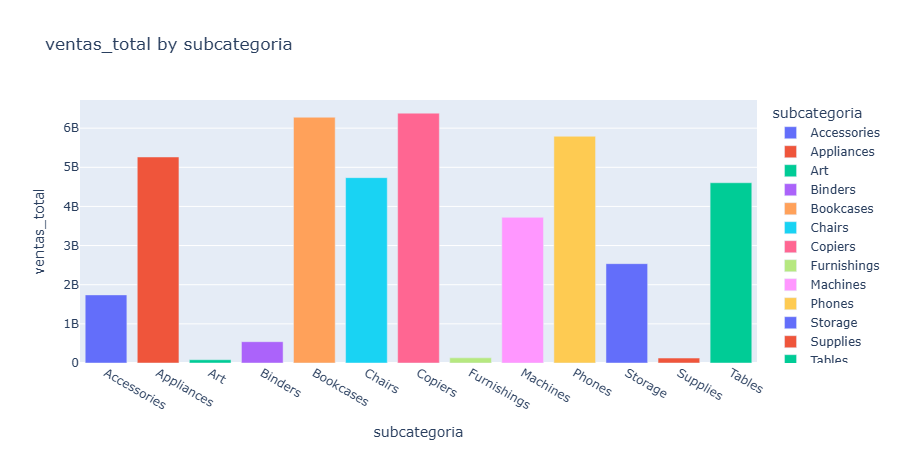

In [4]:
antes = px.bar(subcategorias.sort_values("subcategoria"), x="subcategoria", y="ventas_total",
               color="subcategoria", template="plotly", title="ventas_total by subcategoria")
antes.show()

La versión mejorada aplica los principios de las secciones anteriores:

- Barras **horizontales y ordenadas**, para que los nombres se lean sin girar la cabeza y el ranking salte a la vista.
- **Color con significado**: el de la categoría, el mismo que en el resto de la app; la leyenda tiene tres entradas, no trece.
- Cifras en **millones**, con etiquetas directas solo al final de cada barra, y sin rejilla vertical que compita con los datos.
- Un **título que dice la conclusión**, calculada a partir de los datos.

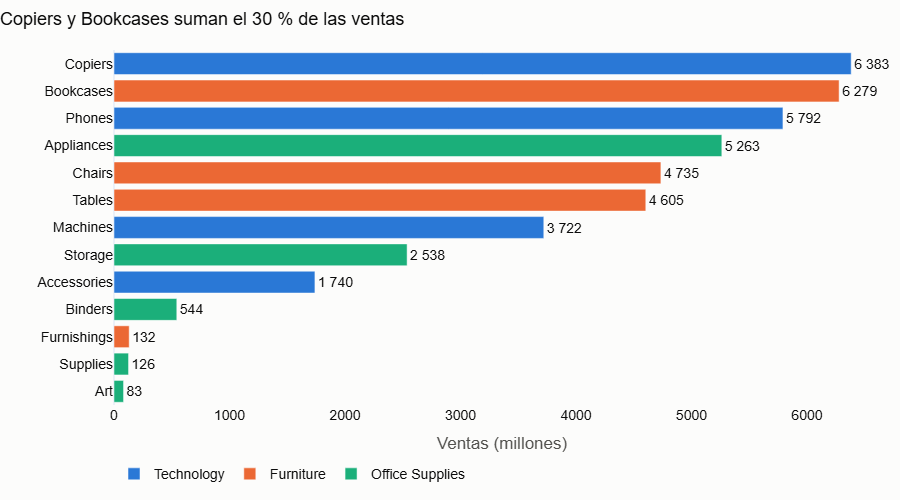

Copiers y Bookcases suman el 30 % de las ventas


In [5]:
orden = subcategorias.sort_values("ventas_total")
orden["ventas_m"] = orden["ventas_total"] / 1e6
top = orden.sort_values("ventas_total", ascending=False).head(2)
cuota = top["ventas_total"].sum() / orden["ventas_total"].sum()
titulo = f"{top['subcategoria'].iloc[0]} y {top['subcategoria'].iloc[1]} suman el {cuota * 100:.0f} % de las ventas"

despues = px.bar(orden, x="ventas_m", y="subcategoria", orientation="h", color="categoria",
                 color_discrete_map=estilo.COLORES_CATEGORIA, text="ventas_m", title=titulo,
                 category_orders={"categoria": list(estilo.COLORES_CATEGORIA)},
                 labels={"ventas_m": "Ventas (millones)", "subcategoria": "", "categoria": ""})
despues.update_traces(texttemplate="%{text:,.0f}", textposition="outside", cliponaxis=False)
despues.update_layout(yaxis={"categoryorder": "total ascending"}, xaxis={"showgrid": False}, height=500)
despues.show()
print(titulo)

Las dos figuras muestran exactamente los mismos números. La segunda se entiende en los cinco segundos de la regla: Copiers (Technology) y Bookcases (Furniture) encabezan el ranking y suman el 30 % de las ventas.

## 5. Temas: `config.toml` y una plantilla de Plotly

Un **tema** fija los colores, fuentes y estilos por defecto de toda la app; con un tema, la consistencia es automática. En una app de Streamlit hay dos capas que deben coincidir:

| Capa | Dónde | Qué controla |
| --- | --- | --- |
| Tema de Streamlit | `.streamlit/config.toml`, sección `[theme]` | Fondo, texto, color primario (botones, enlaces, selección), bordes, paleta de los gráficos nativos |
| Plantilla de Plotly | `estilo.py` (`pio.templates`) | Fuente, colores de serie, fondos, rejillas y márgenes de cada figura de Plotly |

Streamlit lee `config.toml` de la carpeta `.streamlit/` del **directorio desde el que se lanza** la app (también lee uno junto al script principal, con prioridad). Como las apps del repositorio se lanzan desde la raíz, el tema está en `.streamlit/config.toml` de la raíz, igual que exige Streamlit Community Cloud (Módulo 50):

In [6]:
import tomllib

config = Path("../../.streamlit/config.toml")
print(config.read_text(encoding="utf-8"))
tema = tomllib.loads(config.read_text(encoding="utf-8"))["theme"]

# Tema de las apps de Streamlit del repositorio (sección S08).
# Streamlit lee este archivo desde la carpeta donde se lanza la app (la raíz del
# repositorio, también en Streamlit Community Cloud).
# Mantener los colores iguales que en s08-dashboards/practica-ventas/estilo.py.

[theme]
base = "light"
primaryColor = "#2a78d6"
backgroundColor = "#fcfcfb"
secondaryBackgroundColor = "#f1f0ed"
textColor = "#0b0b0b"
linkColor = "#1c5cab"
borderColor = "#e4e3df"
baseRadius = "medium"
chartCategoricalColors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
chartSequentialColors = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#184f95"]



Lo que en una herramienta de BI sería un archivo JSON de tema (`dataColors`, `background`, `foreground`) aquí se reparte entre esas claves. La plantilla de Plotly vive en [`estilo.py`](../practica-ventas/estilo.py) y repite los mismos colores; una comprobación automática evita que se separen:

In [7]:
assert tema["primaryColor"] == estilo.PRIMARIO
assert tema["backgroundColor"] == estilo.FONDO
assert tema["chartCategoricalColors"] == estilo.PALETA
print("Plantilla por defecto de Plotly:", pio.templates.default)
print("Colores por categoría:", estilo.COLORES_CATEGORIA)

Plantilla por defecto de Plotly: plotly_white+ventas
Colores por categoría: {'Technology': '#2a78d6', 'Furniture': '#eb6834', 'Office Supplies': '#1baf7a'}


Al importar `estilo`, la plantilla `"plotly_white+ventas"` pasa a ser la de todas las figuras de Plotly Express (las plantillas se suman con `+`: la segunda sobrescribe a la primera). En la app, cada figura se dibuja con `st.plotly_chart(fig, theme=None)`: `theme=None` le dice a Streamlit que respete la plantilla propia en lugar de aplicar la suya. Un detalle práctico: aun así, Streamlit pinta el área de trazado con su color de fondo secundario cuando el fondo solo viene de la plantilla, así que la app pasa cada figura por `estilo.ajustar(fig)`, que repite los fondos en el propio gráfico.

La paleta categórica es apta para daltonismo: sus colores vecinos se distinguen también con las formas más comunes de deficiencia en la visión del color, y las categorías siempre usan los tres primeros. Aun así, el color nunca va solo: cada serie tiene leyenda o etiqueta.

## 6. Navegación entre páginas

Una app con varias páginas tiene un **punto de entrada** que decide qué página mostrar. Con `st.navigation` y `st.Page` ese archivo, [`app.py`](../practica-ventas/app.py), queda así:

In [8]:
texto = (PRACTICA / "app.py").read_text(encoding="utf-8")
print(texto.split(chr(34) * 3, 2)[2].strip())  # sin el docstring del módulo

from pathlib import Path

import streamlit as st

import comun
import estilo  # noqa: F401  (registra la plantilla de Plotly)
import seguridad

RUTA = Path(__file__).resolve().parent

st.set_page_config(page_title="Ventas", page_icon=":material/storefront:", layout="wide")
st.logo(str(RUTA / "icono-inicio.jpg"), size="large")

inicio = st.Page("paginas/inicio.py", title="Inicio", icon=":material/home:", default=True)
paginas = {
    "": [inicio],
    "Tablero": [
        st.Page("paginas/resumen.py", title="Resumen", icon=":material/dashboard:"),
        st.Page("paginas/medidas.py", title="Medidas de tiempo", icon=":material/calendar_month:"),
        st.Page("paginas/analisis.py", title="Análisis por país", icon=":material/travel_explore:"),
    ],
    "Información": [
        st.Page("paginas/acerca.py", title="Acerca de", icon=":material/info:"),
    ],
}
pagina = st.navigation(paginas, position="sidebar")

with st.sidebar:
    seguridad.panel_acceso()
    comun.barra_lateral()

# 

Las piezas:

| Pieza | Qué hace | Equivalente en una herramienta de BI |
| --- | --- | --- |
| `st.Page("paginas/resumen.py", title=..., icon=...)` | Declara una página a partir de un script | Una pestaña del informe |
| `st.navigation({sección: [páginas]})` | Construye el menú lateral, con secciones, y devuelve la página elegida | El navegador de páginas |
| `default=True` | Página que se abre al entrar | La primera pestaña |
| `pagina.run()` | Ejecuta la página elegida | |
| `st.page_link(pagina)` | Un enlace a otra página, dentro del contenido | Un botón con acción "navegación de página" |
| `st.switch_page(pagina)` | Cambia de página desde el código (por ejemplo, tras pulsar un botón) | |

Todo lo que `app.py` dibuja antes de `pagina.run()` aparece en **todas** las páginas: el logotipo (`st.logo`), los filtros de la barra lateral y el enlace "Inicio" del principio de cada página. Las páginas viven en `paginas/` y no en `pages/`, porque una carpeta `pages/` junto al script principal activa el modo multipágina antiguo de Streamlit, que crea su propio menú.

La portada ([`paginas/inicio.py`](../practica-ventas/paginas/inicio.py)) es un menú: una tarjeta por página, con su `st.page_link` y una frase que dice qué contiene. `AppTest` permite comprobarla sin abrir un navegador:

In [9]:
at = AppTest.from_file(str(PRACTICA / "app.py"), default_timeout=90).run()
print("Excepciones:", len(at.exception))
print("Título:", at.title[0].value)
print("Menú:", [enlace.value for enlace in at.page_link])
for pagina in ["paginas/resumen.py", "paginas/medidas.py", "paginas/analisis.py", "paginas/acerca.py"]:
    at.switch_page(pagina).run()
    print(f"{pagina:22} excepciones: {len(at.exception)} | título: {at.title[0].value}")

Excepciones: 0
Título: Dashboard de ventas
Menú: ['Resumen', 'Análisis por país', 'Medidas de tiempo', 'Acerca de']


paginas/resumen.py     excepciones: 0 | título: Resumen de ventas


paginas/medidas.py     excepciones: 0 | título: Medidas de tiempo


paginas/analisis.py    excepciones: 0 | título: Análisis por país
paginas/acerca.py      excepciones: 0 | título: Acerca de este dashboard


## 7. Marcadores: estados guardados de los filtros

En una herramienta de BI, un **marcador** (bookmark) guarda el estado de una página (filtros, selección, qué se ve) para volver a él con un clic. En Streamlit el estado de la sesión vive en `st.session_state`, así que un marcador es simplemente un **conjunto de valores** que un botón escribe en ese estado.

Los filtros de la app son compartidos: `app.py` dibuja en la barra lateral dos `st.date_input` con `key="desde"` y `key="hasta"`, y cada página los lee de `st.session_state`. Los marcadores se definen en [`comun.py`](../practica-ventas/comun.py):

```python
MARCADORES = {
    "2019-s1": {"nombre": "2019, primer semestre", "desde": dt.date(2019, 1, 1), "hasta": dt.date(2019, 6, 30)},
    "2019-s2": {"nombre": "2019, segundo semestre", "desde": dt.date(2019, 7, 1), "hasta": dt.date(2019, 12, 31)},
    "todo": {"nombre": "Todo el periodo", "desde": INICIO, "hasta": FIN},
}

def aplicar_marcador(clave):
    marcador = MARCADORES[clave]
    st.session_state["desde"] = marcador["desde"]      # se ejecuta antes de dibujar los widgets
    st.session_state["hasta"] = marcador["hasta"]
    if clave == "todo":
        st.query_params.pop("marcador", None)
    else:
        st.query_params["marcador"] = clave             # el marcador queda en la URL

st.button(marcador["nombre"], on_click=aplicar_marcador, args=(clave,),
          type="primary" if clave == activo else "secondary")
```

Tres detalles importan:

1. El botón usa un **callback** (`on_click`). Los callbacks se ejecutan antes de la nueva ejecución del script, cuando los `st.date_input` todavía no existen, así que pueden cambiar su valor. Escribir en `st.session_state["desde"]` después de dibujar el widget lanza un error (sección 10).
2. El marcador se guarda en la **URL** con `st.query_params`. Un enlace a `.../resumen?marcador=2019-s1` abre la app con ese periodo, porque `iniciar_estado()` lee `st.query_params` al empezar la sesión. Es la versión compartible del marcador.
3. El botón del marcador activo usa `type="primary"`, como el estado "seleccionado" de un navegador de marcadores.

Las ventas de cada semestre, calculadas directamente con el modelo:

In [10]:
semestres = {
    "2019-s1": practica.kpis(con, desde="2019-01-01", hasta="2019-06-30")["ventas_total"],
    "2019-s2": practica.kpis(con, desde="2019-07-01", hasta="2019-12-31")["ventas_total"],
}
for clave, total in semestres.items():
    print(clave, estilo.entero(total), "->", estilo.millones(total))

2019-s1 6 805 180 904 -> 6 805.18 M
2019-s2 7 223 003 319 -> 7 223.00 M


Y la misma comprobación dentro de la app: pulsar cada marcador cambia la tarjeta de ventas del resumen y la URL.

In [11]:
at = AppTest.from_file(str(PRACTICA / "app.py"), default_timeout=90).run()
at.switch_page("paginas/resumen.py").run()
for clave, total in semestres.items():
    at.button(key=f"marcador_{clave}").click().run()
    tarjeta = at.metric[0].value
    print(f"{clave}: tarjeta {tarjeta} | esperado {estilo.millones(total)} | URL ?marcador={at.query_params['marcador']}")
    assert tarjeta == estilo.millones(total)
print("Botón resaltado:", [b.label for b in at.button if b.proto.type == "primary"])

2019-s1: tarjeta 6 805.18 M | esperado 6 805.18 M | URL ?marcador=2019-s1


2019-s2: tarjeta 7 223.00 M | esperado 7 223.00 M | URL ?marcador=2019-s2
Botón resaltado: ['2019, segundo semestre']


El primer semestre de 2019 vendió 6 805.18 M y el segundo 7 223.00 M. Un botón "Restablecer filtros" aplica el marcador "Todo el periodo" y vacía los países y categorías elegidos.

## 8. Botones y acciones

En una herramienta de BI, un botón es un objeto con una **acción** asignada. En Streamlit, cada acción tiene su elemento:

| Acción | En Streamlit | Uso en la app |
| --- | --- | --- |
| Navegación de página | `st.page_link(pagina)` o `st.switch_page(pagina)` | Menú de la portada y enlace "Inicio" |
| Atrás / volver al inicio | `st.page_link(inicio, label="Inicio")` escrito en `app.py` | Arriba de cada página, siempre en el mismo sitio |
| Marcador | `st.button(..., on_click=callback)` que escribe en `st.session_state` | Semestres de 2019 y "Restablecer filtros" |
| Obtención de detalles | `@st.dialog` (una ventana con el detalle) o `st.switch_page(..., query_params=...)` | Botón "Ver detalle" de la página de análisis |
| Dirección URL web | `st.link_button("Texto", url)` | Enlaces a documentación externa |
| Descargar | `st.download_button` | Tabla por país en CSV |

Un caso combinado está en la portada: los accesos rápidos aplican un marcador **y** llevan al resumen. El callback fija las fechas y, como `st.button` devuelve `True` en la ejecución siguiente, el cambio de página va en el cuerpo del script:

```python
if st.button("Resumen de 2019, primer semestre", on_click=comun.aplicar_marcador, args=("2019-s1",)):
    st.switch_page("paginas/resumen.py", query_params={"marcador": "2019-s1"})
```

`st.switch_page` borra los parámetros de la URL al cambiar de página salvo los que se le pasan en `query_params`; por eso se repite ahí el marcador.

In [12]:
at = AppTest.from_file(str(PRACTICA / "app.py"), default_timeout=90).run()
at.button(key="inicio_2019-s2").click().run()
print("Página:", at.title[0].value, "| ventas:", at.metric[0].value, "| URL:", dict(at.query_params))

Página: Resumen de ventas | ventas: 7 223.00 M | URL: {'marcador': '2019-s2'}


## 9. Pantallas estrechas

Un tablero diseñado para un monitor ancho se ve diminuto en un teléfono. Streamlit resuelve buena parte del problema sin un diseño aparte: **por debajo de unos 640 píxeles de ancho, las columnas se apilan** una debajo de otra, en el orden en que se escribieron, y la barra lateral se pliega detrás de un botón. Por eso el orden del script importa: primero los KPIs, luego el gráfico principal, luego el detalle.

![La misma página de resumen a 420 píxeles de ancho: las tarjetas y los gráficos se apilan en una columna](captura-movil.png)

Pautas para que el tablero siga siendo útil en pantallas estrechas:

- Pocos elementos por página, en orden de importancia.
- Filtros en la barra lateral, que en el teléfono se oculta y no roba espacio.
- `st.container(horizontal=True)` para filas de tarjetas: salta de línea cuando no caben, en lugar de encoger cada tarjeta.
- Evitar tablas muy anchas y mapas pequeños, difíciles de leer y de tocar; un mapa puede ir acompañado de unas barras con la misma información.

## 10. Errores frecuentes

**Cambiar el valor de un widget después de dibujarlo.** Un marcador escrito en el cuerpo del script, en lugar de en un callback, falla porque el widget ya existe en esa ejecución:

In [13]:
def app_con_error():
    import datetime as dt
    import streamlit as st

    st.date_input("Desde", value=dt.date(2019, 1, 1), key="desde")
    if st.button("2019, segundo semestre"):
        st.session_state["desde"] = dt.date(2019, 7, 1)  # el widget ya se dibujó


at = AppTest.from_function(app_con_error).run()
at.button[0].click().run()
print(at.exception[0].value.splitlines()[0][:110])

`st.session_state['desde']` cannot be modified after the widget with that key is instantiated. Assign `st.sess


La solución es la de la sección 7: `st.button(..., on_click=aplicar_marcador)`.

**Una página que solo funciona dentro de la app.** Si una página lee `st.session_state["desde"]` y el valor solo lo crea `app.py`, abrirla sola (en una prueba, o al reorganizar la app) lanza un `KeyError`. Cada página debe poner sus valores por defecto con `setdefault`, que no pisa un valor existente:

In [14]:
def pagina_fragil():
    import streamlit as st

    st.write(st.session_state["desde"])


def pagina_robusta():
    import datetime as dt
    import streamlit as st

    st.session_state.setdefault("desde", dt.date(2019, 1, 1))
    st.write(st.session_state["desde"])


print("Frágil: ", AppTest.from_function(pagina_fragil).run().exception[0].value.splitlines()[0][:80])
print("Robusta:", AppTest.from_function(pagina_robusta).run().markdown[0].value)

Frágil:  'st.session_state has no key "desde". Did you forget to initialize it? More info


Robusta: `2019-01-01`


En la app, todas las páginas llaman a `comun.filtros()`, que empieza con `iniciar_estado()`; por eso cada página se puede probar sola con `AppTest.from_file("paginas/resumen.py")`.

**Colores que cambian al filtrar.** Si el color se asigna por posición, al quitar una categoría las demás se corren un lugar en la paleta: `Furniture` pasa de naranja a azul y el lector cree que mira otra cosa. Fijar `color_discrete_map` lo evita:

In [15]:
def colores(figura):
    return {traza.name: traza.marker.color for traza in figura.data}


todas = practica.ventas_por(con, "categoria")
sin_tecnologia = practica.ventas_por(con, "categoria", categorias=["Furniture", "Office Supplies"])
for nombre, datos in [("todas", todas), ("sin Technology", sin_tecnologia)]:
    por_posicion = px.bar(datos, x="categoria", y="ventas_total", color="categoria")
    fijo = px.bar(datos, x="categoria", y="ventas_total", color="categoria",
                  color_discrete_map=estilo.COLORES_CATEGORIA)
    print(f"{nombre:15} por posición: {colores(por_posicion)}")
    print(f"{'':15} fijo:         {colores(fijo)}")

todas           por posición: {'Technology': '#2a78d6', 'Furniture': '#eb6834', 'Office Supplies': '#1baf7a'}
                fijo:         {'Technology': '#2a78d6', 'Furniture': '#eb6834', 'Office Supplies': '#1baf7a'}


sin Technology  por posición: {'Furniture': '#2a78d6', 'Office Supplies': '#eb6834'}
                fijo:         {'Furniture': '#eb6834', 'Office Supplies': '#1baf7a'}


**Demasiados gráficos en una página.** Doce gráficos del mismo tamaño no tienen jerarquía y obligan a leerlo todo. Se elige la pregunta principal de la página y el resto va a otras páginas o a un diálogo de detalle (`st.dialog`).

**Elementos decorativos que compiten con los datos.** CSS propio, fondos con imágenes, sombras y bordes gruesos atraen la mirada antes que los números. El tema de `config.toml` y los contenedores con borde fino bastan; Streamlit desaconseja el CSS propio salvo que no haya otra forma.

**Una carpeta `pages/` junto a `st.navigation`.** Si el punto de entrada usa `st.navigation`, una carpeta `pages/` es innecesaria y confunde: es la convención del modo multipágina antiguo. Las páginas van en una carpeta con otro nombre (`paginas/`) y se declaran con `st.Page`.

**Diseñar solo para la pantalla del autor.** Un tablero que se ve bien en un monitor grande puede cortar títulos en un portátil. Conviene revisarlo en una ventana estrecha o con la vista móvil del navegador.

## 11. Ejercicio

Construye una app mínima de dos páginas en una carpeta temporal:

1. Una página **Menú** (la de inicio) con título, el logotipo `icono-inicio.jpg`, el autor y un `st.page_link` a la página de ventas.
2. Una página **Ventas** con un enlace para volver al menú arriba de todo y una tarjeta con las ventas totales del periodo elegido.
3. Dos botones de marcador, "2019, primer semestre" y "2019, segundo semestre", que fijen el periodo con un callback y lo dejen en la URL.
4. Comprueba con `AppTest` que cada marcador muestra las ventas que da `practica.kpis` para ese semestre.

### Solución

In [16]:
import tempfile

carpeta = Path(tempfile.mkdtemp())
archivos = {
    "app.py": '''
import streamlit as st

menu = st.Page("menu.py", title="Menú", icon=":material/home:", default=True)
ventas = st.Page("ventas_pagina.py", title="Ventas", icon=":material/bar_chart:")
st.navigation([menu, ventas]).run()
''',
    "menu.py": f'''
import streamlit as st

st.title("Dashboard de ventas")
st.image(r"{PRACTICA / 'icono-inicio.jpg'}", width=80)
st.caption("Autor: Juliho Castillo Colmenares")
st.page_link("ventas_pagina.py", label="Ver las ventas", icon=":material/bar_chart:")
''',
    "ventas_pagina.py": f'''
import datetime as dt
import sys

import streamlit as st

sys.path.insert(0, r"{PRACTICA}")
import ventas as practica

SEMESTRES = {{
    "2019-s1": ("2019, primer semestre", dt.date(2019, 1, 1), dt.date(2019, 6, 30)),
    "2019-s2": ("2019, segundo semestre", dt.date(2019, 7, 1), dt.date(2019, 12, 31)),
}}


@st.cache_resource
def conexion():
    return practica.conectar()


def aplicar(clave):
    _, desde, hasta = SEMESTRES[clave]
    st.session_state["desde"], st.session_state["hasta"] = desde, hasta
    st.query_params["marcador"] = clave


st.page_link("menu.py", label="Inicio", icon=":material/home:")
st.session_state.setdefault("desde", dt.date(2019, 1, 1))
st.session_state.setdefault("hasta", dt.date(2021, 12, 31))
with st.container(horizontal=True):
    for clave, (nombre, _, _) in SEMESTRES.items():
        st.button(nombre, key=clave, on_click=aplicar, args=(clave,))
desde, hasta = st.session_state["desde"], st.session_state["hasta"]
total = practica.kpis(conexion(), desde=desde, hasta=hasta)["ventas_total"]
st.metric(f"Ventas del {{desde:%d/%m/%Y}} al {{hasta:%d/%m/%Y}}", f"{{total:,}}".replace(",", " "))
''',
}
for nombre, contenido in archivos.items():
    (carpeta / nombre).write_text(contenido.lstrip(), encoding="utf-8")
print(sorted(p.name for p in carpeta.iterdir()))

['app.py', 'menu.py', 'ventas_pagina.py']


In [17]:
mini = AppTest.from_file(str(carpeta / "app.py"), default_timeout=90).run()
print("Menú:", mini.title[0].value, "| enlaces:", [e.value for e in mini.page_link])
mini.switch_page("ventas_pagina.py").run()
print("Sin marcador:", mini.metric[0].label, "=", mini.metric[0].value)
for clave, esperado in semestres.items():
    mini.button(key=clave).click().run()
    valor = mini.metric[0].value
    print(f"{clave}: {valor} | esperado {estilo.entero(esperado)} | URL {dict(mini.query_params)}")
    assert valor == estilo.entero(esperado)

Menú: Dashboard de ventas | enlaces: ['Ver las ventas']


Sin marcador: Ventas del 01/01/2019 al 31/12/2021 = 41 940 958 825
2019-s1: 6 805 180 904 | esperado 6 805 180 904 | URL {'marcador': '2019-s1'}
2019-s2: 7 223 003 319 | esperado 7 223 003 319 | URL {'marcador': '2019-s2'}


Cada marcador deja en la tarjeta las ventas del semestre (6 805 180 904 y 7 223 003 319) y escribe su clave en la URL. Las dos páginas comparten el estado de la sesión, así que si se vuelve al menú y luego a ventas, el periodo elegido se conserva. La app completa de la práctica sigue el mismo esquema, con los filtros en la barra lateral para que estén disponibles en todas las páginas.

## Resumen

- Un buen dashboard tiene jerarquía visual (KPIs arriba, pregunta principal en el centro, detalle abajo), respeta una cuadrícula, es consistente y pasa la regla de los 5 segundos.
- En Streamlit la cuadrícula la dan `st.columns`, `st.container(border=True)` y `st.container(horizontal=True)`; las columnas se apilan en pantallas estrechas.
- El gráfico se elige por la pregunta; los títulos dicen la conclusión, los colores siguen a la entidad y nunca hay dos ejes verticales.
- El tema vive en `.streamlit/config.toml` (`[theme]`) y una plantilla de Plotly en `estilo.py` repite sus colores; `theme=None` la respeta.
- `st.navigation` y `st.Page` organizan las páginas en secciones; `st.page_link` y `st.switch_page` navegan entre ellas; lo que `app.py` dibuja antes de `pagina.run()` aparece en todas.
- Un marcador es un conjunto de valores que un callback escribe en `st.session_state`, y que `st.query_params` deja en la URL para compartirlo.

En el **Módulo 50** se prepara esta app para publicarla gratis en Streamlit Community Cloud, se gestionan sus secretos y se restringe el acceso a los datos con seguridad por filas.